# F15 · Cross-modal detector transfer: analysis, 2026-10-28

Visual analysis of the 2×2 detector × test-modality matrix of `spec/2026-10-28-cross-modal-detector-transfer/`
(`results.md`): the frozen heads `det_rgb` and `det_ir` (F8), each scored on both `video_*_test` splits, launched with

```bash
bash slurm/submit.sh ctcomp3 projects/detection/transfer.py \
    cluster.timeout_min=60 cluster.cpus_per_task=8 cluster.num_workers=8 cluster.mem_gb=32
```

Everything here is **re-scored from the 4 saved detection files** (F15 FR4); no inference is re-run. The breakdowns by
time of day, weather and object size were out of F15's scope ("the analysis is decided once the outputs exist"); this
notebook is that analysis. It measures where the domain shift between the two heads is largest *before* the world model
is involved, which is the baseline H2 needs.

**Headline** (preliminary: no CIs until F6, 8 video pairs):
- **In-domain, the two heads are level on all 6 classes (AP 0.157 RGB vs 0.167 IR), but IR wins clearly on person + car
  (0.385 vs 0.278).** The all-class tie hides IR's lower labelling density for sign, light and bike (R10).
- **Cross-modal, a head keeps 57–67 % of the in-domain AP.** `det_rgb` transfers to IR better than `det_ir` to RGB
  (person + car ratio 0.65 vs 0.57). Person carries most of that: `det_rgb` finds IR persons almost as well as RGB ones
  (0.202 vs 0.215), while `det_ir` on RGB persons drops to 0.077.
- **The test set is far from the training distribution.** Dawn is 28 % of test and < 1 % of training; fog is 15 % and
  0 %; rain is 25 % and 4 %; day is 11 % of test but over half of training.
- **Training coverage does not predict AP; illumination does.** On cars, the only class labelled in every bucket, both
  in-domain heads score their best on dawn (0.43 / 0.46), which neither saw in training. RGB collapses where light is
  bad: dusk into the sun (car 0.14), rain at night (0.10), fog (0.00). IR holds 0.33–0.46 there.
- **Why `det_rgb` beats its own RGB score on IR in most time buckets yet loses on the full split:** dawn holds half
  of all car GT and is the one bucket where it loses (0.308 vs 0.430). Weighting the buckets by GT reproduces the
  full-split car AP (0.340 vs 0.304 against 0.340 vs 0.300). The F15 ratio 0.61 is ÷ `det_ir` on IR, not ÷ `det_rgb` on
  RGB (that one is 0.65; 0.90 on person + car).
- **In glare, rain and fog, `det_rgb` does better on IR images than on its own RGB images** (car, dusk 0.26 vs 0.14,
  rain 0.22 vs 0.10, fog 0.11 vs 0.00). There the input image is the bottleneck, not the head.
- **AP grows with object size, and on IR it keeps growing:** ≥ 128 px objects reach AP 0.92–0.94 on IR test with either
  head, while RGB test plateaus at about 0.3 from 64 px up. F15's APs/M/L for RGB test carry an area-convention bias
  (§5.1) that F6 should fix.

In [1]:
import contextlib
import copy
import hashlib
import io
import json
import math
from collections import Counter
from multiprocessing import get_context
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval

from irwm.data.classes import CLASS_NAMES, LABEL_TO_CATEGORY_ID, normalised_area, size_bucket
from irwm.data.detection import FlirDetectionDataset
from irwm.data.flir import FlirSplit, split_dir
from irwm.detection.coco_val import coco_map
from irwm.detection.inference import load_detections
from irwm.utils.paths import load_env, output_root

load_env()  # FLIR data root for FlirSplit
# Run dir and detections copied from the cluster into <repo>/outputs; falls back to $IRWM_OUTPUT_ROOT.
OUT = Path("../outputs")
if not (OUT / "detection/detections").is_dir():
    OUT = output_root()

RUN_DIR = OUT / "detection/2026-10-28/13-49-32"  # SLURM 5526475, W&B j3apbc75
TRANSFER = json.loads((RUN_DIR / "transfer.json").read_text())
HEADS = ["det_rgb", "det_ir"]
MODS = ["rgb", "thermal"]
HEAD_MOD = {"det_rgb": "rgb", "det_ir": "thermal"}  # modality each head was trained on
CELLS = [(h, m) for h in HEADS for m in MODS]

# The saved files must be the ones transfer.json scored.
for h, m in CELLS:
    d = TRANSFER["detections"][h][m]
    assert hashlib.sha256((OUT / d["path"]).read_bytes()).hexdigest() == d["sha256"], (h, m)
print(f"transfer.json at {TRANSFER['git']['commit'][:7]} (dirty={TRANSFER['git']['dirty']}), "
      f"{TRANSFER['device']['name']}; 4 detection files match their SHA-256")

/home/leonardo.ulloa/projects/ir-world-model/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/home/leonardo.ulloa/projects/ir-world-model/.venv/lib/python3.11/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)
/home/leonardo.ulloa/projects/ir-world-model/third_party/detrex/detrex/config/config.py:18: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


transfer.json at 1179143 (dirty=False), Tesla V100S-PCIE-32GB; 4 detection files match their SHA-256


In [2]:
# Plot style, same as detector_training_results.ipynb: hue = the head's training modality (RGB blue, thermal orange,
# categorical slots 1-2). Within a hue, solid = in-domain cell, hatched = cross-modal cell, so the 4 cells never
# rely on colour alone.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
MOD_LABEL = {"rgb": "RGB", "thermal": "IR"}
INK, MUTED, GRID, REF = "#0b0b0b", "#52514e", "#e6e5e0", "#a8a7a2"
SHARE_FILL = "#f0efec"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False, "hatch.linewidth": 0.8,
})


def cell_label(h, m):
    return f"{h} → {MOD_LABEL[m]} test"


def cell_style(h, m):
    c = MOD_COLOR[HEAD_MOD[h]]
    if HEAD_MOD[h] == m:
        return dict(facecolor=c, edgecolor=c, linewidth=1.0)
    return dict(facecolor="white", edgecolor=c, hatch="////", linewidth=1.0)


def share_style(h):
    return dict(facecolor=SHARE_FILL, edgecolor=MOD_COLOR[HEAD_MOD[h]], hatch="...", linewidth=1.0)


def cell_handles(share=False):
    handles = [Patch(**cell_style(h, m), label=cell_label(h, m)) for h, m in CELLS]
    if share:
        handles += [Patch(**share_style(h), label=f"share of {h} training frames") for h in HEADS]
    return handles


def cell_legend(ax, share=False, **kw):
    ax.legend(handles=cell_handles(share), **kw)


def table(header, rows):
    fmt = lambda v: f"{v:.3f}" if isinstance(v, float) else ("–" if v is None else str(v))
    lines = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    lines += ["| " + " | ".join(fmt(v) for v in r) + " |" for r in rows]
    display(Markdown("\n".join(lines)))

## 0. Conditions: time of day and weather

FLIR stores tags per **video** in each split's `index.json`; a frame inherits its video's tags (`video_id`). The tags are
incomplete and not always consistent between the two files of an RGB/thermal pair, so the test conditions are set
**once per pair** in the table below, and checked against every tag that exists. Three choices are not in the tags:

- **`1628739688` (parking lot, 226 frames) → night.** No time tag. Every frame is dark sky under headlight glare.
- **`1629771558` (I-205, 565 frames) → dusk.** No time tag; its description says "near sunset", and the sun is on the
  horizon. Dusk is a **fourth time bucket** besides day, night and dawn: it is 15 % of the test set, matches the
  `sunset`/`dusk` tags of the train split, and fits none of the other three.
- **`00004653` (Detroit, 428 frames) → day.** Only the thermal file carries `day`; the RGB file has no time tag.

**Weather buckets: clear, cloudy, rain, fog.** `cloudy`, `rain` and `fog` are FLIR tags. There is no `clear` tag, so
**clear is defined as the easy condition: no weather tag, daylight, and no glare.** In test that is only the Detroit
pair (428 frames). Two pairs have no weather tag but bad light, so they are **in no weather bucket** (`none` in the
tables): I-205 drives into the setting sun, and the parking lot is at night under headlight glare. They still count in
the time buckets. The cloudy pair is the dawn video, the only `cloudy` test video; cloudy is ≈ 10 % of training.

Train frames follow a fixed rule on their video's tags: time = `dawn` if tagged dawn, else `dusk` if tagged dusk or
sunset (in train, `sunset` always comes with `day` and `dusk` with `night`), else `night`, else `day`, else
`untagged`. Weather = `fog`, else `rain`, else `cloudy`, else **`clear` if the time is `day`**, else `none`. No train
video carries a glare tag, so "no glare" cannot be applied to train: train clear is untagged daylight. The training set of a head is the train split **minus frames
with no kept box**, exactly what F8 trained on (`FlirDetectionDataset(..., filter_empty=True)`).

In [3]:
# FLIR video filename prefix, shared by the RGB and thermal file of a test pair -> (time, weather).
PAIR_CONDITIONS = {
    "1636345164": ("night", "fog"),
    "1636345107": ("night", "fog"),
    "1627530658": ("night", "rain"),
    "1627531624": ("night", "rain"),
    "1628739688": ("night", "none"),   # untagged: dark sky, headlight glare
    "1624582918": ("dawn", "cloudy"),
    "1629771558": ("dusk", "none"),    # untagged: "near sunset", driving into the sun
    "00004653": ("day", "clear"),      # only the thermal file is tagged day; no weather tag, no glare
}
TIMES = ["day", "dawn", "dusk", "night"]
WEATHERS = ["clear", "cloudy", "rain", "fog"]  # "none": no weather tag but not the easy condition


def videos(m, s):
    return json.loads((split_dir(m, s) / "index.json").read_text())["videos"]


def train_time(tags):
    for t, keys in [("dawn", {"dawn"}), ("dusk", {"dusk", "sunset"}), ("night", {"night"}), ("day", {"day"})]:
        if tags & keys:
            return t
    return "untagged"


def train_weather(tags):
    for w in ["fog", "rain", "cloudy"]:
        if w in tags:
            return w
    return "clear" if train_time(tags) == "day" else "none"


# Test: every frame gets its pair's condition; the table must agree with every existing tag.
TEST_SPLIT = {m: FlirSplit.load(m, "test") for m in MODS}
TEST_COND = {}  # modality -> image_id -> (time, weather)
VIDEO_ROWS = []
for m in MODS:
    cond = {}
    for v in videos(m, "test"):
        t, w = PAIR_CONDITIONS[v["filename"].split("_")[0]]
        tags = set(v["tags"])
        assert tags & {"day", "dawn", "dusk", "sunset", "night"} <= {t}, (v["filename"], tags)
        assert tags & {"rain", "fog", "cloudy"} == {w} & {"rain", "fog", "cloudy"}, (v["filename"], tags)
        cond[v["id"]] = (t, w)
    TEST_COND[m] = {r.image_id: cond[r.video_id] for r in TEST_SPLIT[m].records}
    n = Counter(r.video_id for r in TEST_SPLIT[m].records)
    if m == "rgb":
        VIDEO_ROWS = [[v["filename"].split("_")[0], *cond[v["id"]], n[v["id"]]] for v in videos(m, "test")]

# Train: the frames each head trained on.
TRAIN_SHARE = {}  # head -> {"time": {bucket: share}, "weather": {...}}
TRAIN_N = {}
for h in HEADS:
    m = HEAD_MOD[h]
    split = FlirSplit.load(m, "train")
    tags = {v["id"]: set(v["tags"]) for v in videos(m, "train")}
    ids = set(FlirDetectionDataset(split, filter_empty=True)._image_ids())
    recs = [r for r in split.records if r.image_id in ids]
    TRAIN_N[h] = len(recs)
    tc = Counter(train_time(tags[r.video_id]) for r in recs)
    wc = Counter(train_weather(tags[r.video_id]) for r in recs)
    TRAIN_SHARE[h] = {"time": {k: tc[k] / len(recs) for k in TIMES + ["untagged"]},
                      "weather": {k: wc[k] / len(recs) for k in WEATHERS + ["none"]}}

table(["pair", "time", "weather", "frames per modality"], sorted(VIDEO_ROWS, key=lambda r: (TIMES.index(r[1]), r[2])))
rows = []
for kind, keys in [("time", TIMES + ["untagged"]), ("weather", WEATHERS + ["none"])]:
    for k in keys:
        n_test = sum(1 for c in TEST_COND["rgb"].values() if c[0 if kind == "time" else 1] == k)
        rows.append([kind, k, f"{n_test:,} ({n_test / len(TEST_COND['rgb']):.1%})",
                     *[f"{TRAIN_SHARE[h][kind][k]:.1%}" for h in HEADS]])
table(["", "bucket", "test frames (each modality)", f"det_rgb train ({TRAIN_N['det_rgb']:,})",
       f"det_ir train ({TRAIN_N['det_ir']:,})"], rows)
assert all(Counter(c for c in TEST_COND[m].values()) == Counter(c for c in TEST_COND["rgb"].values()) for m in MODS)

| pair | time | weather | frames per modality |
|---|---|---|---|
| 00004653 | day | clear | 428 |
| 1624582918 | dawn | cloudy | 1033 |
| 1629771558 | dusk | none | 565 |
| 1636345164 | night | fog | 338 |
| 1636345107 | night | fog | 208 |
| 1628739688 | night | none | 226 |
| 1627530658 | night | rain | 540 |
| 1627531624 | night | rain | 411 |

|  | bucket | test frames (each modality) | det_rgb train (10,038) | det_ir train (10,462) |
|---|---|---|---|---|
| time | day | 428 (11.4%) | 52.1% | 53.8% |
| time | dawn | 1,033 (27.6%) | 0.3% | 0.0% |
| time | dusk | 565 (15.1%) | 10.7% | 10.6% |
| time | night | 1,723 (46.0%) | 36.3% | 30.9% |
| time | untagged | 0 (0.0%) | 0.5% | 4.6% |
| weather | clear | 428 (11.4%) | 42.9% | 44.9% |
| weather | cloudy | 1,033 (27.6%) | 8.9% | 8.6% |
| weather | rain | 951 (25.4%) | 4.0% | 3.8% |
| weather | fog | 546 (14.6%) | 0.0% | 0.0% |
| weather | none | 791 (21.1%) | 44.2% | 42.6% |

- **Test conditions barely overlap the training distribution.** The two biggest test buckets are night (46 %) and dawn
  (28 %). Dawn is **0.3 % of `det_rgb`'s and 0 % of `det_ir`'s training frames**. Fog never occurs in training (0 %),
  and rain only 4 %. Day, over half of each training set, is a single test pair (11 %).
- **Both heads saw almost the same mix of conditions** (within 6 points in every bucket). So a difference between the heads in one bucket is a feature or modality
  effect, not a training-coverage effect.
- **The easy condition is rare in test.** Clear (untagged daylight) is 43–45 % of training but 11 % of test (one pair).
  Cloudy is 9 % of training and 28 % of test (the dawn pair).
- 4.6 % of `det_ir`'s training frames come from thermal videos with no time tag (Santa Barbara, 2018); they count in no
  time bucket.

## Re-scoring

One `COCOeval.evaluate()` per (head, test modality), with F8's `coco_map` settings (`to_coco_gt("normalised")`,
default `iouThrs`/`maxDets`) plus extra area ranges for §5. A subset of frames (a time or weather bucket) is then
scored by accumulating only that subset's per-image results (`evalImgs`). This equals `COCOeval` run on the subset,
because per-image matching does not depend on the other images; a check below confirms it on one bucket.
**`COCOeval.accumulate(p)` with a restricted `p.imgIds` cannot be used for this:** it indexes `evalImgs` with positions
in the *new* image list (`cocoeval.py:349,358`), so it silently scores the first *n* frames of the split instead of the
subset. AP over a subset is the mean over the classes that have at least one GT box in it.

The evaluation takes several minutes per cell, so the metrics are cached under
`$IRWM_OUTPUT_ROOT/detection/transfer_analysis/`, keyed by the detection SHA-256s, the subsets and the area ranges.
The full-split numbers must reproduce `transfer.json` `cells` exactly.

In [4]:
# Area ranges in 640x512-normalised px². The first four are COCOeval's defaults ("all", S, M, L).
AREAS = {"all": [0, 1e5**2], "S": [0, 32**2], "M": [32**2, 96**2], "L": [96**2, 1e5**2]}
SQRT_EDGES = [0, 8, 16, 32, 64, 128, None]  # √area bins for §5
FINE = [f"{lo}–{hi}" if hi else f"≥ {lo}" for lo, hi in zip(SQRT_EDGES[:-1], SQRT_EDGES[1:])]
for name, lo, hi in zip(FINE, SQRT_EDGES[:-1], SQRT_EDGES[1:]):
    AREAS[name] = [lo**2, hi**2 if hi else 1e5**2]

# §1.1: a test condition is covered by training if its time bucket and its weather bucket each have at least
# MIN_TRAIN frames in *both* heads' training sets (§0 buckets, "none" included).
MIN_TRAIN = 500
TRAIN_COUNT = {h: {kind: {b: round(sh * TRAIN_N[h]) for b, sh in shares.items()} for kind, shares in TRAIN_SHARE[h].items()}
               for h in HEADS}
COVERED = {(t, w) for t, w in PAIR_CONDITIONS.values()
           if all(TRAIN_COUNT[h]["time"][t] >= MIN_TRAIN and TRAIN_COUNT[h]["weather"][w] >= MIN_TRAIN for h in HEADS)}

# modality -> subset name -> image ids (None = the whole split)
SUBSETS = {}
for m in MODS:
    s = {"all": None}
    for t in TIMES:
        s[f"time={t}"] = sorted(i for i, c in TEST_COND[m].items() if c[0] == t)
    for w in WEATHERS + ["none"]:
        s[f"weather={w}"] = sorted(i for i, c in TEST_COND[m].items() if c[1] == w)
        s[f"night,weather={w}"] = sorted(i for i, c in TEST_COND[m].items() if c == ("night", w))
    s["covered"] = sorted(i for i, c in TEST_COND[m].items() if c in COVERED)
    SUBSETS[m] = s


def mean_valid(p):
    v = p[p > -1]
    return float(v.mean()) if v.size else math.nan


def restrict(E, img_ids):
    """A shallow copy of an evaluated ``COCOeval`` whose ``evalImgs`` (laid out [class][area][image]) hold only
    ``img_ids``, so ``accumulate()`` scores exactly that subset."""
    pe = E._paramsEval
    pos = {i: n for n, i in enumerate(pe.imgIds)}
    idx = [pos[i] for i in img_ids]
    K0, A0, I0 = len(pe.catIds), len(pe.areaRng), len(pe.imgIds)
    sub = copy.copy(E)
    sub._paramsEval = copy.copy(pe)
    sub._paramsEval.imgIds = list(img_ids)
    sub.params = copy.copy(sub._paramsEval)
    sub.evalImgs = [E.evalImgs[k * A0 * I0 + a * I0 + i] for k in range(K0) for a in range(A0) for i in idx]
    return sub


def summarise(E, img_ids):
    """AP / AP50 overall and per class at every area range, maxDets 100, on a subset of images."""
    S = E if img_ids is None else restrict(E, img_ids)
    with contextlib.redirect_stdout(io.StringIO()):
        S.accumulate()
    p = S.params
    prec = S.eval["precision"][..., -1]  # [T IoUs, R recalls, K classes, A areas] at maxDets 100
    out = {}
    for a, area in enumerate(AREAS):
        r = {"AP": mean_valid(prec[:, :, :, a]), "AP50": mean_valid(prec[0, :, :, a])}
        for k, c in enumerate(CLASS_NAMES):
            kk = p.catIds.index(LABEL_TO_CATEGORY_ID[k])
            r[f"AP_{c}"] = mean_valid(prec[:, :, kk, a])
            r[f"AP50_{c}"] = mean_valid(prec[0, :, kk, a])
        for key in ["AP", "AP50"]:
            pc = [r[f"{key}_person"], r[f"{key}_car"]]
            r[f"{key}_person_car"] = math.nan if any(map(math.isnan, pc)) else float(np.mean(pc))
        out[area] = r
    return out


def evaluate_cell(job):
    """(head, modality, dt_area) -> subset -> area -> metrics. dt_area="native" is coco_map's convention."""
    h, m, dt_area = job
    gt = TEST_SPLIT[m].to_coco_gt("normalised")
    dets = load_detections(OUT / TRANSFER["detections"][h][m]["path"])["detections"]
    with contextlib.redirect_stdout(io.StringIO()):
        coco_gt = COCO()
        coco_gt.dataset = gt
        coco_gt.createIndex()
        coco_dt = coco_gt.loadRes(dets)  # sets each detection's area to w·h in native FLIR px
        if dt_area == "normalised":
            for a in coco_dt.anns.values():
                img = coco_gt.imgs[a["image_id"]]
                a["area"] = normalised_area(a["bbox"][2], a["bbox"][3], img["width"], img["height"])
        E = COCOeval(coco_gt, coco_dt, iouType="bbox")
        E.params.areaRng, E.params.areaRngLbl = list(AREAS.values()), list(AREAS)
        E.evaluate()
    subsets = SUBSETS[m] if dt_area == "native" else {"all": None}
    return job, {name: summarise(E, ids) for name, ids in subsets.items()}


# Thermal frames are 640x512, so normalising detection areas only changes the RGB-test cells.
JOBS = [(h, m, "native") for h, m in CELLS] + [(h, "rgb", "normalised") for h in HEADS]
cache_key = hashlib.sha256(json.dumps({
    "version": 4, "areas": AREAS, "jobs": JOBS, "subsets": SUBSETS,
    "sha256": {f"{h}/{m}": TRANSFER["detections"][h][m]["sha256"] for h, m in CELLS},
}, sort_keys=True).encode()).hexdigest()
CACHE = OUT / "detection/transfer_analysis" / TRANSFER["encoder"]["encoder_tag"] / "eval.json"
if CACHE.is_file() and json.loads(CACHE.read_text())["key"] == cache_key:
    cached = json.loads(CACHE.read_text())
    print(f"loaded {CACHE} ({cached['created_with']})")
else:
    with get_context("fork").Pool(3, maxtasksperchild=1) as pool:  # ≈ 4 GB per worker
        results = pool.map(evaluate_cell, JOBS, chunksize=1)
    cached = {"key": cache_key, "created_with": "notebooks/detector_transfer_results.ipynb",
              "results": [{"job": list(j), "metrics": r} for j, r in results]}
    CACHE.parent.mkdir(parents=True, exist_ok=True)
    CACHE.write_text(json.dumps(cached))
    print(f"wrote {CACHE}")
EVAL = {tuple(e["job"]): e["metrics"] for e in cached["results"]}


def M(h, m, subset="all", area="all", dt_area="native"):
    return EVAL[(h, m, dt_area)][subset][area]


# Reproduce transfer.json exactly (it was scored with coco_map, i.e. native detection areas).
COCO_KEY = {"APs": "S", "APm": "M", "APl": "L"}
for h, m in CELLS:
    for key, ref in TRANSFER["cells"][h][m].items():
        if key == "AP75":
            continue
        area = COCO_KEY.get(key, "all")
        val = M(h, m, area=area)["AP" if key in COCO_KEY else key]
        assert (math.isnan(ref) and math.isnan(val)) or abs(val - ref) < 1e-12, (h, m, key, val, ref)
print("full-split metrics reproduce transfer.json cells exactly (19 keys × 4 cells)")

# Subset check: det_ir on IR test, day bucket, scored directly by COCOeval on that bucket's GT and detections only.
ids = set(SUBSETS["thermal"]["time=day"])
gt = TEST_SPLIT["thermal"].to_coco_gt("normalised")
gt = {**gt, "images": [i for i in gt["images"] if i["id"] in ids],
      "annotations": [a for a in gt["annotations"] if a["image_id"] in ids]}
dets = [d for d in load_detections(OUT / TRANSFER["detections"]["det_ir"]["thermal"]["path"])["detections"]
        if d["image_id"] in ids]
direct = coco_map(gt, dets)
for key, val in direct.items():
    sub = M("det_ir", "thermal", "time=day", COCO_KEY.get(key, "all"))["AP" if key in COCO_KEY else key] \
        if key != "AP75" else val
    assert (math.isnan(val) and math.isnan(sub)) or abs(sub - val) < 1e-12, (key, sub, val)
print("subset scoring equals a direct coco_map on the subset (det_ir, IR test, day)")

loaded ../outputs/detection/transfer_analysis/dinov2_vitb14reg_448x560_l3-6-9-12_pca1152/eval.json (notebooks/detector_transfer_results.ipynb)
full-split metrics reproduce transfer.json cells exactly (19 keys × 4 cells)


subset scoring equals a direct coco_map on the subset (det_ir, IR test, day)


## 1. The 2×2 matrix

Rows are heads, columns are test splits; each cell is scored against **its test split's own annotations**. Solid
outline = in-domain. Top: all 6 classes (the primary metric). Bottom: person + car only, the subset that R10 says to
read for the modality comparison, because thermal test GT omits most signs, lights and bikes that RGB GT labels.

Two ratios describe a cross-modal cell, and they answer different questions:
- **÷ in-domain on the same split** (F15's `transfer_ratio`, printed in the cells): `det_rgb` on IR ÷ `det_ir` on IR.
  Same GT, same frames, only the head changes. This is "how good is a foreign head on this modality".
- **÷ the same head in-domain** (last columns of the table): `det_rgb` on IR ÷ `det_rgb` on RGB. Same head, different
  GT and frames. This is "how much does this head lose when the modality changes".

| cell | AP | AP50 | AP p+c | AP50 p+c | AP ÷ in-domain head, same split | AP ÷ same head in-domain | AP p+c ÷ same head in-domain |
|---|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.157 | 0.331 | 0.278 | 0.537 | – | – | – |
| det_rgb → IR test | 0.102 | 0.205 | 0.251 | 0.477 | 0.615 | 0.654 | 0.904 |
| det_ir → RGB test | 0.089 | 0.201 | 0.157 | 0.307 | 0.569 | 0.535 | 0.408 |
| det_ir → IR test | 0.167 | 0.334 | 0.385 | 0.713 | – | – | – |

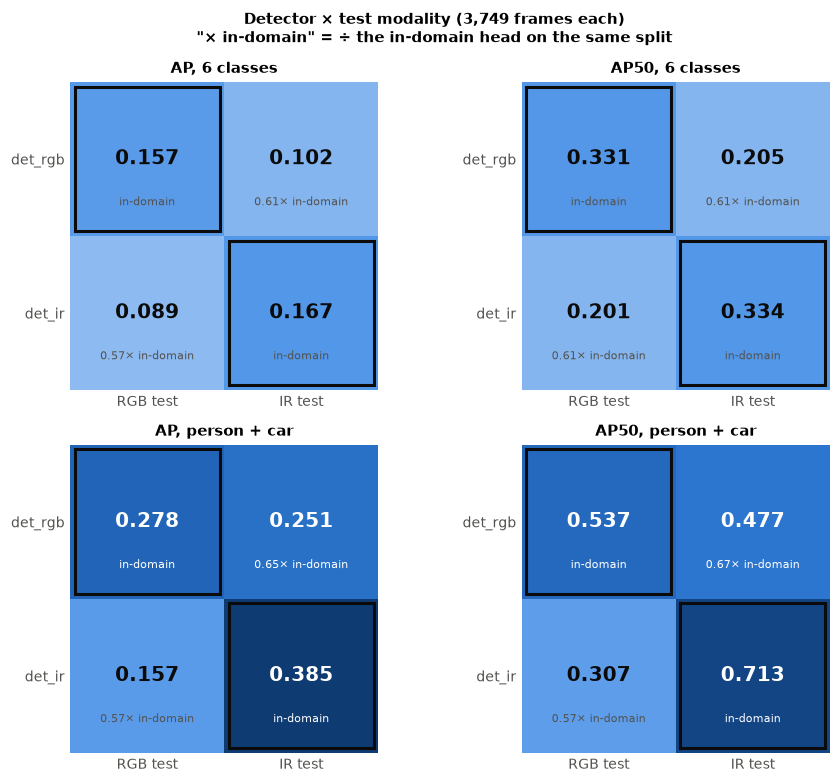

In [5]:
BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # sequential blue 100→700
CMAP = LinearSegmentedColormap.from_list("blue", BLUE_RAMP)
PANELS = [("AP", "AP, 6 classes"), ("AP50", "AP50, 6 classes"),
          ("AP_person_car", "AP, person + car"), ("AP50_person_car", "AP50, person + car")]
IN_DOMAIN = {m: h for h, m in HEAD_MOD.items()}  # test modality -> its in-domain head


def transfer_ratio(h, m, key, subset="all"):
    """Cell ÷ the in-domain head on the same split and subset (F15's transfer_ratio on the full split)."""
    return M(h, m, subset)[key] / M(IN_DOMAIN[m], m, subset)[key]


def matrix_plot(subset="all", what=""):
    n = len(TEST_COND["rgb"]) if subset == "all" else len(SUBSETS["rgb"][subset])
    fig, axes = plt.subplots(2, 2, figsize=(8.6, 7.2))
    for ax, (key, title) in zip(axes.flat, PANELS):
        V = np.array([[M(h, m, subset)[key] for m in MODS] for h in HEADS])
        ax.imshow(V, cmap=CMAP, vmin=0, vmax=max(0.4, V.max()) if "50" not in key else max(0.8, V.max()))
        for i, h in enumerate(HEADS):
            for j, m in enumerate(MODS):
                dark = V[i, j] > (0.2 if "50" not in key else 0.4)
                ax.text(j, i, f"{V[i, j]:.3f}", ha="center", va="center", fontsize=13, fontweight="bold",
                        color="white" if dark else INK)
                if HEAD_MOD[h] == m:
                    ax.add_patch(plt.Rectangle((j - 0.47, i - 0.47), 0.94, 0.94, fill=False, ec=INK, lw=2))
                    ax.text(j, i + 0.3, "in-domain", ha="center", fontsize=7.5, color="white" if dark else MUTED)
                else:
                    ax.text(j, i + 0.3, f"{transfer_ratio(h, m, key, subset):.2f}× in-domain", ha="center",
                            fontsize=7.5, color="white" if dark else MUTED)
        ax.set_xticks([0, 1], [f"{MOD_LABEL[m]} test" for m in MODS])
        ax.set_yticks([0, 1], HEADS)
        ax.tick_params(length=0)
        ax.grid(False)
        for s in ax.spines.values():
            s.set_visible(False)
        ax.set_title(title)
    fig.suptitle(f"Detector × test modality ({n:,} frames each{what})\n"
                 f"\"× in-domain\" = ÷ the in-domain head on the same split", fontweight="bold", fontsize=10)
    fig.tight_layout()

    rows = [[cell_label(h, m), *[M(h, m, subset)[k] for k, _ in PANELS],
             *([transfer_ratio(h, m, "AP", subset), M(h, m, subset)["AP"] / M(h, HEAD_MOD[h], subset)["AP"],
                M(h, m, subset)["AP_person_car"] / M(h, HEAD_MOD[h], subset)["AP_person_car"]]
               if HEAD_MOD[h] != m else [None] * 3)]
            for h, m in CELLS]
    table(["cell", "AP", "AP50", "AP p+c", "AP50 p+c", "AP ÷ in-domain head, same split",
           "AP ÷ same head in-domain", "AP p+c ÷ same head in-domain"], rows)


# On the full split the ratios are F15's.
for h, m in CELLS:
    if HEAD_MOD[h] != m:
        for key, _ in PANELS:
            assert abs(transfer_ratio(h, m, key) - TRANSFER["transfer_ratio"][h][m][key]) < 1e-12, (h, m, key)
matrix_plot()

- **On all 6 classes the in-domain cells tie** (0.157 vs 0.167 AP, 0.331 vs 0.334 AP50). **On person + car, IR is ahead
  by 0.11 AP and 0.18 AP50** (0.385 vs 0.278; 0.713 vs 0.537), which is the H1 direction. The all-class number is
  pulled down on IR by classes whose IR labels are sparse (R10, §2), so person + car is the cleaner reading.
- **The off-diagonal cells keep 57–67 % of the in-domain value.** The drop is not symmetric: on person + car,
  `det_rgb` on IR keeps 0.65 of `det_ir`'s AP, while `det_ir` on RGB keeps only 0.57 of `det_rgb`'s. A head trained on
  RGB features generalises to IR features better than the reverse.
- **Per head, `det_rgb` keeps 0.65 of its own AP on IR (0.102 / 0.157) and 0.90 on person + car (0.251 / 0.278);
  `det_ir` keeps 0.53 on RGB (0.089 / 0.167) and 0.41 on person + car.** The RGB head barely loses persons and cars
  when moved to IR; the IR head loses most of them when moved to RGB.
- **On IR test, `det_rgb` (0.251) is closer to `det_ir` (0.385) than `det_ir` on RGB (0.157) is to `det_rgb` (0.278).**
  This is the domain-shift baseline for H2: before any world model is involved, swapping modality already costs about
  40 % of AP.

### 1.1 The 2×2 matrix on conditions covered by training

§0 shows that most test frames come from conditions the heads barely saw in training. This section re-scores the
2×2 on the test frames whose conditions **are** in training: a frame is kept if its time bucket **and** its weather
bucket (§0) each have **at least 500 frames in both heads' training sets**. The table below gives the training counts
and which buckets pass. Dawn (≤ 33 frames), rain (399) and fog (0) fail, so the dawn/cloudy, rain and fog pairs are
dropped. The kept pairs are day/clear (Detroit), dusk (I-205, `none`) and the night parking lot (`none`). These are
also the only pairs whose raw FLIR tags are all ≥ 500 in training (the two `none` pairs carry no condition tag).
AP is still the mean over the classes with GT in the subset, so check the GT counts below before comparing with §1.

|  | bucket | det_rgb train frames | det_ir train frames | ≥ 500 in both |
|---|---|---|---|---|
| time | day | 5,233 | 5,632 | yes |
| time | dawn | 33 | 0 | no |
| time | dusk | 1,077 | 1,113 | yes |
| time | night | 3,644 | 3,235 | yes |
| weather | clear | 4,304 | 4,701 | yes |
| weather | cloudy | 898 | 900 | yes |
| weather | rain | 399 | 399 | no |
| weather | fog | 0 | 0 | no |
| weather | none | 4,437 | 4,462 | yes |

| pair | time | weather | frames per modality | kept |
|---|---|---|---|---|
| 00004653 | day | clear | 428 | yes |
| 1624582918 | dawn | cloudy | 1033 | no |
| 1629771558 | dusk | none | 565 | yes |
| 1636345164 | night | fog | 338 | no |
| 1636345107 | night | fog | 208 | no |
| 1628739688 | night | none | 226 | yes |
| 1627530658 | night | rain | 540 | no |
| 1627531624 | night | rain | 411 | no |

**GT boxes per class in the covered subset (RGB / IR test)**

| person | bike | car | motor | light | sign |
|---|---|---|---|---|---|
| 2,603 / 2,606 | 24 / 0 | 13,943 / 12,934 | 0 / 0 | 5,914 / 2,324 | 5,567 / 2,183 |

| cell | AP | AP50 | AP p+c | AP50 p+c | AP ÷ in-domain head, same split | AP ÷ same head in-domain | AP p+c ÷ same head in-domain |
|---|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.178 | 0.351 | 0.317 | 0.584 | – | – | – |
| det_rgb → IR test | 0.175 | 0.346 | 0.277 | 0.524 | 0.662 | 0.984 | 0.874 |
| det_ir → RGB test | 0.084 | 0.181 | 0.168 | 0.319 | 0.472 | 0.318 | 0.440 |
| det_ir → IR test | 0.265 | 0.513 | 0.382 | 0.704 | – | – | – |

**Full split vs covered subset**

| cell | AP full | AP covered | AP p+c full | AP p+c covered | AP50 p+c full | AP50 p+c covered |
|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.157 | 0.178 | 0.278 | 0.317 | 0.537 | 0.584 |
| det_rgb → IR test | 0.102 | 0.175 | 0.251 | 0.277 | 0.477 | 0.524 |
| det_ir → RGB test | 0.089 | 0.084 | 0.157 | 0.168 | 0.307 | 0.319 |
| det_ir → IR test | 0.167 | 0.265 | 0.385 | 0.382 | 0.713 | 0.704 |

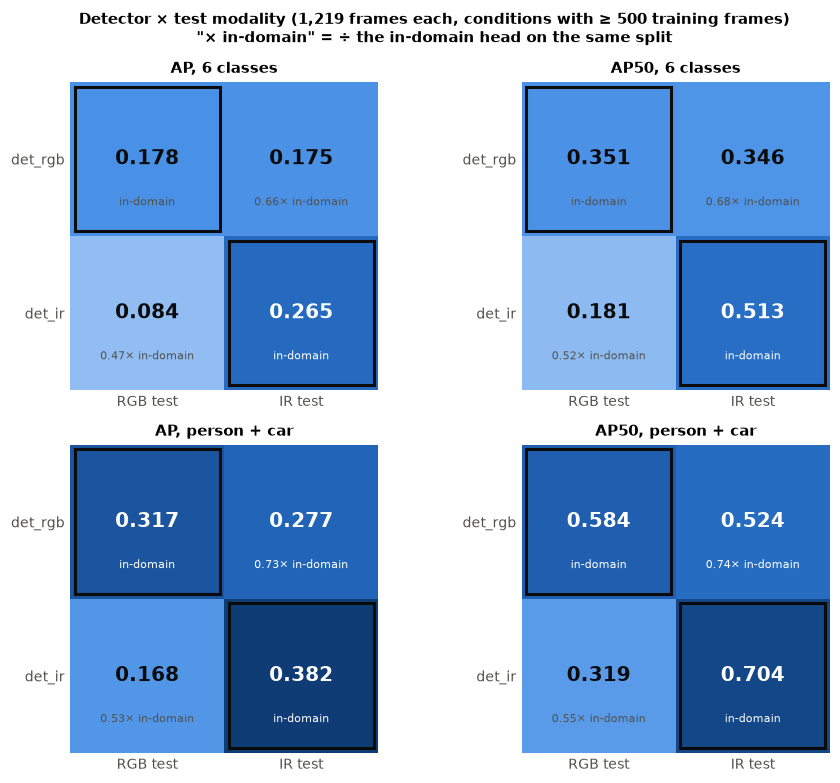

In [6]:
rows = []
for kind, keys in [("time", TIMES), ("weather", WEATHERS + ["none"])]:
    for k in keys:
        ok = all(TRAIN_COUNT[h][kind][k] >= MIN_TRAIN for h in HEADS)
        rows.append([kind, k, *[f"{TRAIN_COUNT[h][kind][k]:,}" for h in HEADS], "yes" if ok else "no"])
table(["", "bucket", "det_rgb train frames", "det_ir train frames", f"≥ {MIN_TRAIN} in both"], rows)

table(["pair", "time", "weather", "frames per modality", "kept"],
      [[*r, "yes" if tuple(r[1:3]) in COVERED else "no"]
       for r in sorted(VIDEO_ROWS, key=lambda r: (TIMES.index(r[1]), r[2]))])

gt = {m: Counter(CLASS_NAMES[int(lab)] for r in TEST_SPLIT[m].records if r.image_id in set(SUBSETS[m]["covered"])
                 for lab in r.labels) for m in MODS}
display(Markdown("**GT boxes per class in the covered subset (RGB / IR test)**"))
table(CLASS_NAMES, [[f"{gt['rgb'][c]:,} / {gt['thermal'][c]:,}" for c in CLASS_NAMES]])

matrix_plot("covered", ", conditions with ≥ 500 training frames")

display(Markdown("**Full split vs covered subset**"))
table(["cell", "AP full", "AP covered", "AP p+c full", "AP p+c covered", "AP50 p+c full", "AP50 p+c covered"],
      [[cell_label(h, m), *[M(h, m, s)[k] for k in ["AP", "AP_person_car", "AP50_person_car"] for s in ["all", "covered"]]]
       for h, m in CELLS])

- **On person + car, IR is still ahead in-domain, by less:** 0.382 vs 0.317 AP (0.704 vs 0.584 AP50), against
  0.385 vs 0.278 on the full split. The gap narrows because `det_rgb` on RGB rises (0.278 → 0.317) while `det_ir` on IR
  stays flat (0.385 → 0.382). The dropped rain and fog pairs are where RGB collapsed (§4), so in conditions covered by
  training the H1 direction is smaller but still there.
- **The cross-modal asymmetry gets wider.** On person + car, `det_rgb` on IR keeps 0.73 of `det_ir`'s AP (full split
  0.65), and `det_ir` on RGB keeps 0.53 of `det_rgb`'s (full split 0.57). Per head, `det_rgb` keeps 0.87 of its own
  person + car AP on IR and `det_ir` keeps 0.44 on RGB. So the asymmetry in §1 is not caused by the uncovered
  conditions: the IR head transfers to RGB worse even on conditions both heads trained on.
- **Do not compare the 6-class AP across columns here.** No motor is labelled in the subset, and the 24 bikes are
  RGB-only. So RGB AP is the mean of 5 classes, one of them bike at ≈ 0 (0.001 for `det_rgb`), and IR AP is the mean
  of 4. `det_rgb` keeping "0.98" of its AP on IR (0.175 vs 0.178) comes from this. Without bike, `det_rgb` on RGB is
  0.222. The jump of `det_ir` on IR from 0.167 to 0.265 also comes mostly from motor (0.080) and bike (≈ 0) dropping
  out of the mean.
- **Small subset:** 3 pairs and 1,219 frames per modality, one pair per time bucket, and the dusk pair has only cars.
  Preliminary until F6, as in the rest of the notebook.

## 2. AP per class

COCO AP (IoU 0.50:0.95) per class for the 4 cells. Under each class: the number of GT boxes of that class in the RGB
and the IR test split (non-crowd). Where the two counts differ a lot (sign, light, bike), a cross-modal bar compares
different labelling densities, not only features (R10).

| class | GT RGB | GT IR | IR / RGB | det_rgb → RGB test | det_rgb → IR test | det_ir → RGB test | det_ir → IR test |
|---|---|---|---|---|---|---|---|
| person | 11278 | 12323 | 1.090 | 0.215 | 0.202 | 0.077 | 0.359 |
| bike | 446 | 113 | 0.250 | 0.012 | 0.000 | 0.003 | 0.000 |
| car | 30893 | 30517 | 0.990 | 0.340 | 0.300 | 0.237 | 0.410 |
| motor | 3573 | 3314 | 0.930 | 0.191 | 0.050 | 0.151 | 0.080 |
| light | 17818 | 6758 | 0.380 | 0.044 | 0.039 | 0.024 | 0.081 |
| sign | 17213 | 5660 | 0.330 | 0.136 | 0.023 | 0.042 | 0.070 |

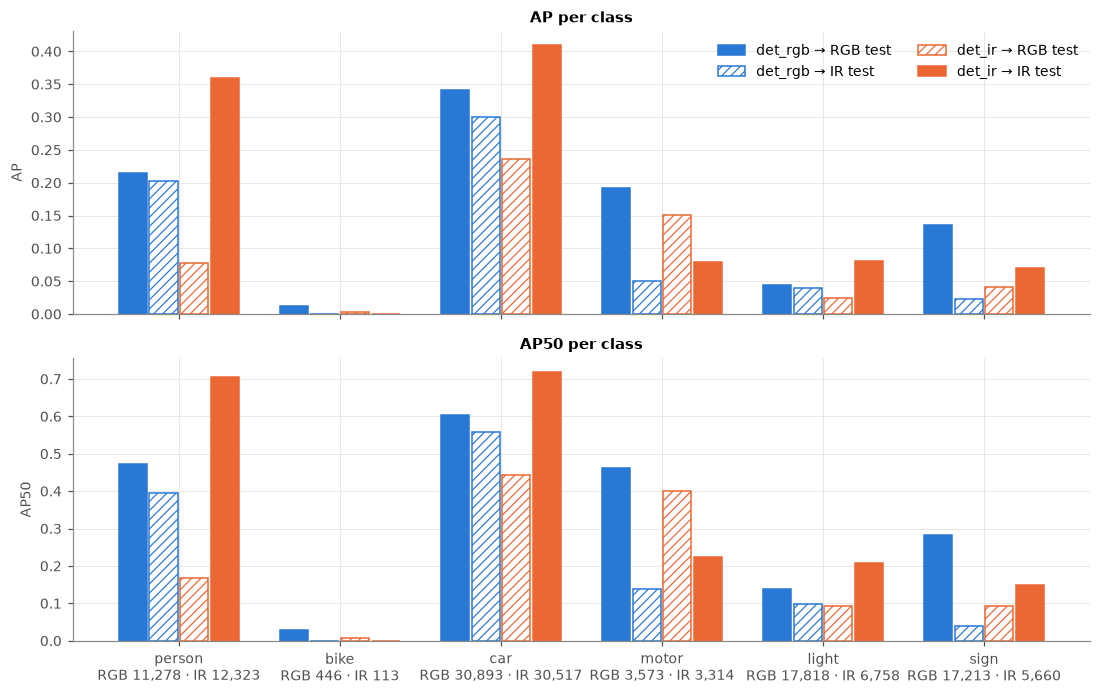

In [7]:
def gt_counts(m, ids=None):
    """Non-crowd GT boxes per class and per √area bin (normalised px) in a test split."""
    keep = None if ids is None else set(ids)
    per_class, per_bin = Counter(), Counter()  # per_bin also counts COCO's "S"/"M"/"L"
    for r in TEST_SPLIT[m].records:
        if keep is not None and r.image_id not in keep:
            continue
        for b, lab in zip(r.boxes, r.labels):
            per_class[CLASS_NAMES[int(lab)]] += 1
            area = normalised_area(float(b[2]), float(b[3]), r.width, r.height)
            per_bin[size_bucket(area)] += 1
            s = math.sqrt(area)
            per_bin[next(n for n, lo, hi in zip(FINE, SQRT_EDGES[:-1], SQRT_EDGES[1:]) if s >= lo and (hi is None or s < hi))] += 1
    return per_class, per_bin


GT_CLASS, GT_BIN = {}, {}
for m in MODS:
    GT_CLASS[m], GT_BIN[m] = gt_counts(m)

fig, axes = plt.subplots(2, 1, figsize=(10, 6.4), sharex=True)
x = np.arange(len(CLASS_NAMES))
w = 0.19
for ax, key in zip(axes, ["AP", "AP50"]):
    for i, (h, m) in enumerate(CELLS):
        v = [M(h, m)[f"{key}_{c}"] for c in CLASS_NAMES]
        ax.bar(x + (i - 1.5) * w, v, w * 0.92, **cell_style(h, m))
    ax.set_ylabel(key)
    ax.set_ylim(0, None)
    ax.set_title(f"{key} per class")
axes[1].set_xticks(x, [f"{c}\nRGB {GT_CLASS['rgb'][c]:,} · IR {GT_CLASS['thermal'][c]:,}" for c in CLASS_NAMES])
cell_legend(axes[0], loc="upper right", ncols=2)
fig.tight_layout()

rows = [[c, GT_CLASS["rgb"][c], GT_CLASS["thermal"][c], round(GT_CLASS["thermal"][c] / GT_CLASS["rgb"][c], 2),
         *[M(h, m)[f"AP_{c}"] for h, m in CELLS]] for c in CLASS_NAMES]
table(["class", "GT RGB", "GT IR", "IR / RGB", *[cell_label(h, m) for h, m in CELLS]], rows)

- **Person is where the modalities differ most.** `det_ir` on IR reaches 0.359 AP, 1.7× `det_rgb` on RGB (0.215). The
  transfer is lopsided: `det_rgb` finds IR persons nearly as well as RGB ones (0.202), while `det_ir` on RGB persons
  falls to 0.077. What the RGB head learned about persons carries over to thermal features; the reverse does not.
- **Car is the most stable class**, labelled 1:1 in both splits: 0.30–0.41 in three cells; only `det_ir` on RGB drops
  (0.237).
- **Motor goes the other way.** RGB in-domain (0.191) beats IR in-domain (0.080), and `det_ir` on RGB motorcycles
  (0.151) beats `det_ir` on IR motorcycles. All motorcycles are in one pair (the dawn video), so this is one scene.
- **Sign and light cross-modal cells are not comparable (R10).** IR test has 0.33× the signs and 0.38× the lights of RGB
  test on the same frames. `det_rgb` on IR signs (0.023) is scored against GT that omits most signs it may find.
- **Bike is ≈ 0 everywhere** (446 RGB / 113 IR test boxes, 422 / 113 of them in one video).

## 3. AP by time of day

Each group of bars is one time bucket. Within it: `det_rgb` on RGB and on IR test, then the **share of `det_rgb`'s
training frames** in that bucket (dotted, light fill), then the same three for `det_ir`. AP and share are both
fractions, read on the same 0–1 scale. The x labels give the test frames per bucket (identical for both modalities,
the videos are pairs). Top: AP over the classes present in the bucket. Bottom: **AP of car**, the only class with GT
in every bucket of both modalities, at about the same density (table below the figure). The class mix changes a lot
between buckets (dusk is car only, the rain pairs have no person) and between modalities within a bucket (R10), so the
top row compares different class sets; the car row is the like-for-like comparison.

| time | test frames | det_rgb train | det_ir train | AP rgb→RGB | AP rgb→IR | AP ir→RGB | AP ir→IR | AP car rgb→RGB | AP car rgb→IR | AP car ir→RGB | AP car ir→IR |
|---|---|---|---|---|---|---|---|---|---|---|---|
| day | 428 | 52.1% | 53.8% | 0.199 | 0.226 | 0.123 | 0.291 | 0.379 | 0.396 | 0.289 | 0.401 |
| dawn | 1033 | 0.3% | 0.0% | 0.158 | 0.091 | 0.097 | 0.157 | 0.430 | 0.308 | 0.296 | 0.460 |
| dusk | 565 | 10.7% | 10.6% | 0.138 | 0.257 | 0.067 | 0.340 | 0.138 | 0.257 | 0.067 | 0.340 |
| night | 1723 | 36.3% | 30.9% | 0.214 | 0.209 | 0.083 | 0.304 | 0.216 | 0.260 | 0.185 | 0.398 |

**GT boxes per class in each bucket (RGB / IR test)**

| time | person | bike | car | motor | light | sign |
|---|---|---|---|---|---|---|
| day | 2,070 / 1,928 | 24 / 0 | 6,444 / 4,570 | 0 / 0 | 5,914 / 2,324 | 5,341 / 2,183 |
| dawn | 8,129 / 9,173 | 422 / 113 | 15,525 / 15,474 | 3,573 / 3,314 | 11,904 / 4,434 | 11,067 / 3,381 |
| dusk | 0 / 0 | 0 / 0 | 6,821 / 7,234 | 0 / 0 | 0 / 0 | 0 / 0 |
| night | 1,079 / 1,222 | 0 / 0 | 2,103 / 3,239 | 0 / 0 | 0 / 0 | 805 / 96 |

**Car: per-bucket AP vs the full split** (weights = car GT boxes in that bucket and test split)

| cell | day (GT share) | dawn (GT share) | dusk (GT share) | night (GT share) | GT-weighted mean | full split |
|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.379 (21%) | 0.430 (50%) | 0.138 (22%) | 0.216 (7%) | 0.340 | 0.340 |
| det_rgb → IR test | 0.396 (15%) | 0.308 (51%) | 0.257 (24%) | 0.260 (11%) | 0.304 | 0.300 |
| det_ir → RGB test | 0.289 (21%) | 0.296 (50%) | 0.067 (22%) | 0.185 (7%) | 0.236 | 0.237 |
| det_ir → IR test | 0.401 (15%) | 0.460 (51%) | 0.340 (24%) | 0.398 (11%) | 0.416 | 0.410 |

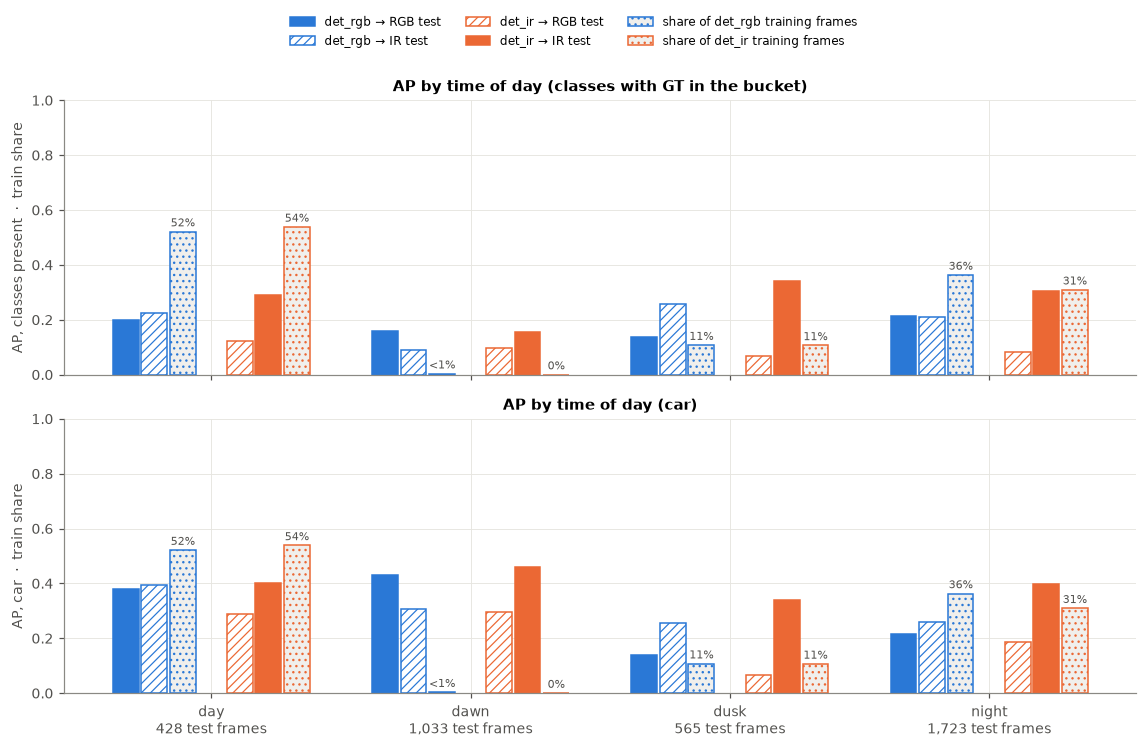

In [8]:
def condition_plot(kind, buckets):
    fig, axes = plt.subplots(2, 1, figsize=(10.5, 6.8), sharex=True)
    x = np.arange(len(buckets))
    w = 0.11
    slots = [("det_rgb", "rgb"), ("det_rgb", "thermal"), ("det_rgb", None), None,
             ("det_ir", "rgb"), ("det_ir", "thermal"), ("det_ir", None)]
    offsets = (np.arange(len(slots)) - (len(slots) - 1) / 2) * w
    for ax, key in zip(axes, ["AP", "AP_car"]):
        for off, slot in zip(offsets, slots):
            if slot is None:
                continue
            h, m = slot
            if m is None:
                share = [TRAIN_SHARE[h][kind][b] for b in buckets]
                ax.bar(x + off, share, w * 0.9, **share_style(h))
                for xi, s in zip(x + off, share):
                    ax.text(xi, s + 0.01, f"{s:.0%}" if s >= 0.01 or s == 0 else "<1%", ha="center",
                            va="bottom", fontsize=7, color=MUTED)
            else:
                ap = [M(h, m, f"{kind}={b}")[key] for b in buckets]
                ax.bar(x + off, ap, w * 0.9, **cell_style(h, m))
                for xi, v in zip(x + off, ap):
                    if v < 0.005:  # a zero-height bar would read as missing
                        ax.text(xi, 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=7, color=MUTED)
        ax.set_ylabel(f"{'AP, classes present' if key == 'AP' else 'AP, car'}  ·  train share")
        ax.set_ylim(0, 1.0)
    n = Counter(c[0 if kind == "time" else 1] for c in TEST_COND["rgb"].values())
    axes[1].set_xticks(x, [f"{b}\n{n[b]:,} test frames" for b in buckets])
    fig.legend(handles=cell_handles(share=True), loc="upper center", ncols=3, fontsize=8,
               bbox_to_anchor=(0.5, 1.0))
    what = "time of day" if kind == "time" else "weather"
    axes[0].set_title(f"AP by {what} (classes with GT in the bucket)")
    axes[1].set_title(f"AP by {what} (car)")
    fig.tight_layout(rect=(0, 0, 1, 0.92))

    rows = []
    for b in buckets:
        rows.append([b, n[b], *[f"{TRAIN_SHARE[h][kind][b]:.1%}" for h in HEADS],
                     *[M(h, m, f"{kind}={b}")["AP"] for h, m in CELLS],
                     *[M(h, m, f"{kind}={b}")["AP_car"] for h, m in CELLS]])
    short = [f"{h[4:]}→{MOD_LABEL[m]}" for h, m in CELLS]
    table([kind, "test frames", "det_rgb train", "det_ir train", *[f"AP {s}" for s in short],
           *[f"AP car {s}" for s in short]], rows)

    display(Markdown("**GT boxes per class in each bucket (RGB / IR test)**"))
    rows = []
    for b in buckets:
        c = {m: gt_counts(m, SUBSETS[m][f"{kind}={b}"])[0] for m in MODS}
        rows.append([b, *[f"{c['rgb'][k]:,} / {c['thermal'][k]:,}" for k in CLASS_NAMES]])
    table([kind, *CLASS_NAMES], rows)


condition_plot("time", TIMES)

# Why the bars do not average to the full-split AP: the full split pools every bucket, so each bucket weighs by its
# number of GT boxes. For one class, the GT-weighted mean of the bucket APs is close to the pooled AP (not exact:
# pooling also ranks detections of different buckets against each other).
display(Markdown("**Car: per-bucket AP vs the full split** (weights = car GT boxes in that bucket and test split)"))
rows = []
for h, m in CELLS:
    n = {b: gt_counts(m, SUBSETS[m][f"time={b}"])[0]["car"] for b in TIMES}
    wmean = sum(n[b] * M(h, m, f"time={b}")["AP_car"] for b in TIMES) / sum(n.values())
    rows.append([cell_label(h, m), *[f"{M(h, m, f'time={b}')['AP_car']:.3f} ({n[b] / sum(n.values()):.0%})" for b in TIMES],
                 wmean, M(h, m)["AP_car"]])
table(["cell", *[f"{b} (GT share)" for b in TIMES], "GT-weighted mean", "full split"], rows)

Read the **car** row for comparisons between buckets. The top row changes class sets between buckets (the table above:
dusk is car only, night has no light/bike/motor, and IR night has 96 signs against RGB's 805).
- **Training share does not explain AP.** Dawn is < 1 % of either training set, yet it gives both in-domain heads their
  best car AP (0.430 RGB, 0.460 IR). Day is over half of training and is not better (0.379 / 0.401). The dawn video is
  well lit, overcast, with dense traffic (Detroit), so dawn as a tag says little about illumination.
- **Illumination drives the gap.** In the dusk pair (I-205, driving into the setting sun), RGB car AP falls to 0.138
  while IR keeps 0.340. At night RGB has 0.216 against IR's 0.398. By day the two are level (0.379 / 0.401).
- **At dusk and at night, `det_rgb` scores better on IR images than on its own RGB images** (car 0.257 vs 0.138 and
  0.260 vs 0.216). The RGB head can read thermal features; it loses because the RGB image itself is degraded. That is
  the thermal advantage the Mission expects, and it shows up even in a head never trained on IR.
- **Why `det_rgb` looks better on IR in most buckets but worse on the full split.** On cars it beats its own RGB
  score at day, dusk and night, and loses only at dawn (0.308 vs 0.430). But dawn holds half of all car GT (50 % RGB,
  51 % IR), so it dominates the pooled number: the GT-weighted mean of the bucket APs gives 0.340 (RGB) vs 0.304
  (IR), matching the full-split 0.340 vs 0.300. The bars are not wrong; the buckets are very unequal in size. On all
  6 classes the gap is wider because the dawn video also holds almost all motor, bike, light and sign GT.
- **Cross-modal cost is largest at dawn**, where in-domain is strongest: car 0.430 → 0.308 for `det_rgb` on IR and
  0.460 → 0.296 for `det_ir` on RGB.

## 4. AP by weather

Same layout as §3, with the weather buckets of §0 (the 791 frames of the two `none` pairs are in no bucket). Each
bucket is one or two video pairs, so **weather and time are confounded**: clear is day, cloudy is dawn, rain and fog
are night. The table after the figure therefore also splits the **night** frames by weather tag. Night has no clear
frames (clear needs daylight), so there the reference is the untagged parking-lot pair (`none`, dry, headlight glare).

**Fog is kept, but it is a small bucket.** Its labels are correct. Each fog frame has one pedestrian and one parked
car, labelled in both modalities. The car is far away and static (the camera does not move), so it is the same box in
all 546 frames. It is visible in thermal and hidden by fog in RGB, so RGB car AP in fog measures exactly that one
object.

| weather | test frames | det_rgb train | det_ir train | AP rgb→RGB | AP rgb→IR | AP ir→RGB | AP ir→IR | AP car rgb→RGB | AP car rgb→IR | AP car ir→RGB | AP car ir→IR |
|---|---|---|---|---|---|---|---|---|---|---|---|
| clear | 428 | 42.9% | 44.9% | 0.199 | 0.226 | 0.123 | 0.291 | 0.379 | 0.396 | 0.289 | 0.401 |
| cloudy | 1033 | 8.9% | 8.6% | 0.158 | 0.091 | 0.097 | 0.157 | 0.430 | 0.308 | 0.296 | 0.460 |
| rain | 951 | 4.0% | 3.8% | 0.123 | 0.111 | 0.049 | 0.164 | 0.101 | 0.220 | 0.047 | 0.327 |
| fog | 546 | 0.0% | 0.0% | 0.124 | 0.428 | 0.077 | 0.616 | 0.000 | 0.105 | 0.000 | 0.443 |

**GT boxes per class in each bucket (RGB / IR test)**

| weather | person | bike | car | motor | light | sign |
|---|---|---|---|---|---|---|
| clear | 2,070 / 1,928 | 24 / 0 | 6,444 / 4,570 | 0 / 0 | 5,914 / 2,324 | 5,341 / 2,183 |
| cloudy | 8,129 / 9,173 | 422 / 113 | 15,525 / 15,474 | 3,573 / 3,314 | 11,904 / 4,434 | 11,067 / 3,381 |
| rain | 0 / 0 | 0 / 0 | 879 / 1,563 | 0 / 0 | 0 / 0 | 579 / 96 |
| fog | 546 / 544 | 0 / 0 | 546 / 546 | 0 / 0 | 0 / 0 | 0 / 0 |

**Night frames only, by weather**

| weather | night test frames | AP rgb→RGB | AP rgb→IR | AP ir→RGB | AP ir→IR | AP car rgb→RGB | AP car rgb→IR | AP car ir→RGB | AP car ir→IR |
|---|---|---|---|---|---|---|---|---|---|
| none | 226 | 0.332 | 0.215 | 0.200 | 0.434 | 0.513 | 0.400 | 0.517 | 0.537 |
| rain | 951 | 0.123 | 0.111 | 0.049 | 0.164 | 0.101 | 0.220 | 0.047 | 0.327 |
| fog | 546 | 0.124 | 0.428 | 0.077 | 0.616 | 0.000 | 0.105 | 0.000 | 0.443 |

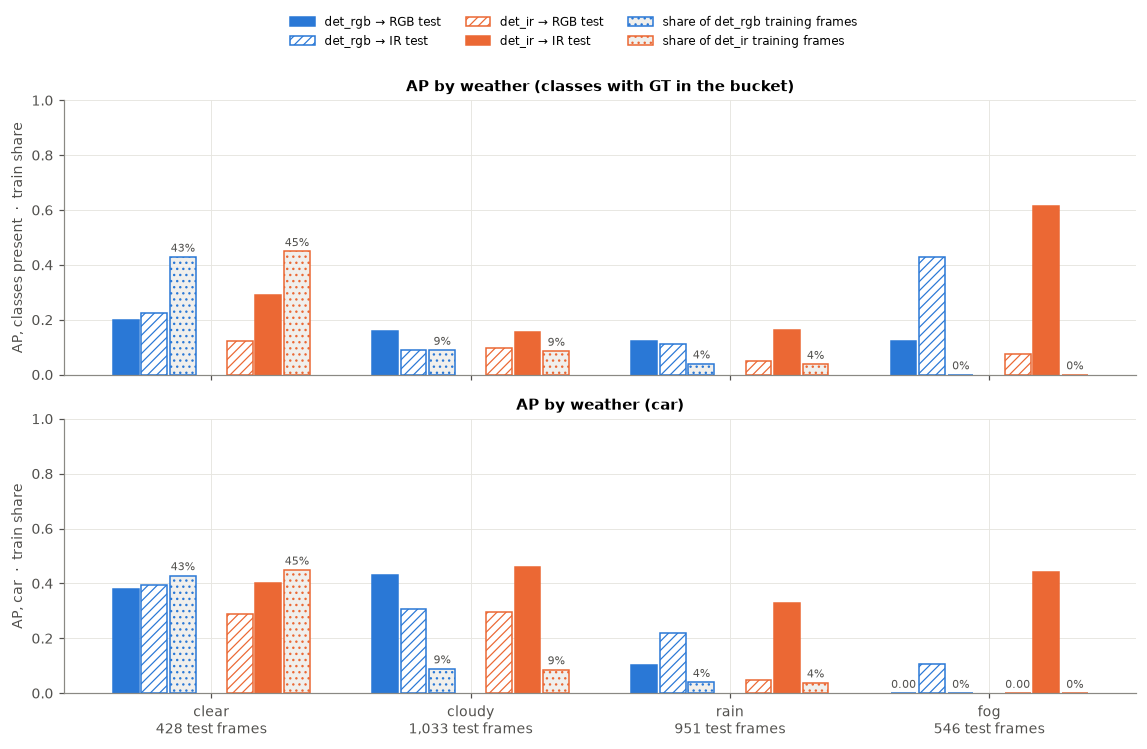

In [9]:
condition_plot("weather", WEATHERS)

n_night = Counter(c[1] for c in TEST_COND["rgb"].values() if c[0] == "night")
rows = [[w, n_night[w], *[M(h, m, f"night,weather={w}")["AP"] for h, m in CELLS],
         *[M(h, m, f"night,weather={w}")["AP_car"] for h, m in CELLS]] for w in ["none", "rain", "fog"]]
short = [f"{h[4:]}→{MOD_LABEL[m]}" for h, m in CELLS]
display(Markdown("**Night frames only, by weather**"))
table(["weather", "night test frames", *[f"AP {s}" for s in short], *[f"AP car {s}" for s in short]], rows)

- **Clear and cloudy are the day and dawn pairs of §3**, so their numbers are the same; the weather axis adds rain
  and fog. In the easy condition (clear) the two in-domain heads are level on cars (0.379 RGB / 0.401 IR), and IR is
  ahead on all classes present (0.291 vs 0.199).
- **At night, rain and fog hurt RGB far more than IR.** Against the dry night pair (`none`, car 0.513 RGB / 0.537 IR,
  a tie), rain takes RGB to 0.101 (−80 %) and IR to 0.327 (−39 %). Fog takes RGB to 0.000 and IR to 0.443 (−18 %).
  Both heads saw the same weather in training (rain 4 %, fog 0 %), so the RGB/IR difference here is the sensor, not
  training coverage.
- **RGB car AP in fog is 0.000 for both heads because the fog hides the one parked car from the RGB camera**, while it
  is visible in thermal (§4 intro). This is a real effect, measured on one object.
- **As in §3, `det_rgb` does better on IR images than on its own RGB images in rain (car 0.220 vs 0.101) and fog
  (0.105 vs 0.000).** Bad weather degrades the RGB input more than moving the RGB head to IR features does.
- **The fog all-class AP (top row, IR 0.616) is the mean of person and car only**, the two classes labelled there; it is
  not comparable with clear or cloudy, which include sign, light, motor and bike.

## 5. AP vs object size

Sizes are √area of the GT box in a 640×512-normalised frame, so a bucket covers the same physical objects in both
modalities (F2). Left: COCO's S/M/L (< 32², 32²–96², ≥ 96²). Right: finer √area bins, with the number of GT boxes per
bin and modality underneath. COCO counts an unmatched detection in a size range by **its own area**.

| cell | 0–8 | 8–16 | 16–32 | 32–64 | 64–128 | ≥ 128 |
|---|---|---|---|---|---|---|
| det_rgb → RGB test | 0.052 | 0.116 | 0.244 | 0.402 | 0.385 | 0.337 |
| det_rgb → IR test | 0.009 | 0.038 | 0.136 | 0.236 | 0.447 | 0.918 |
| det_ir → RGB test | 0.008 | 0.035 | 0.138 | 0.294 | 0.305 | 0.287 |
| det_ir → IR test | 0.026 | 0.113 | 0.224 | 0.293 | 0.483 | 0.936 |
| GT boxes RGB | 27550 | 26609 | 18321 | 5591 | 2533 | 617 |
| GT boxes IR | 9715 | 22062 | 18535 | 5251 | 2614 | 508 |

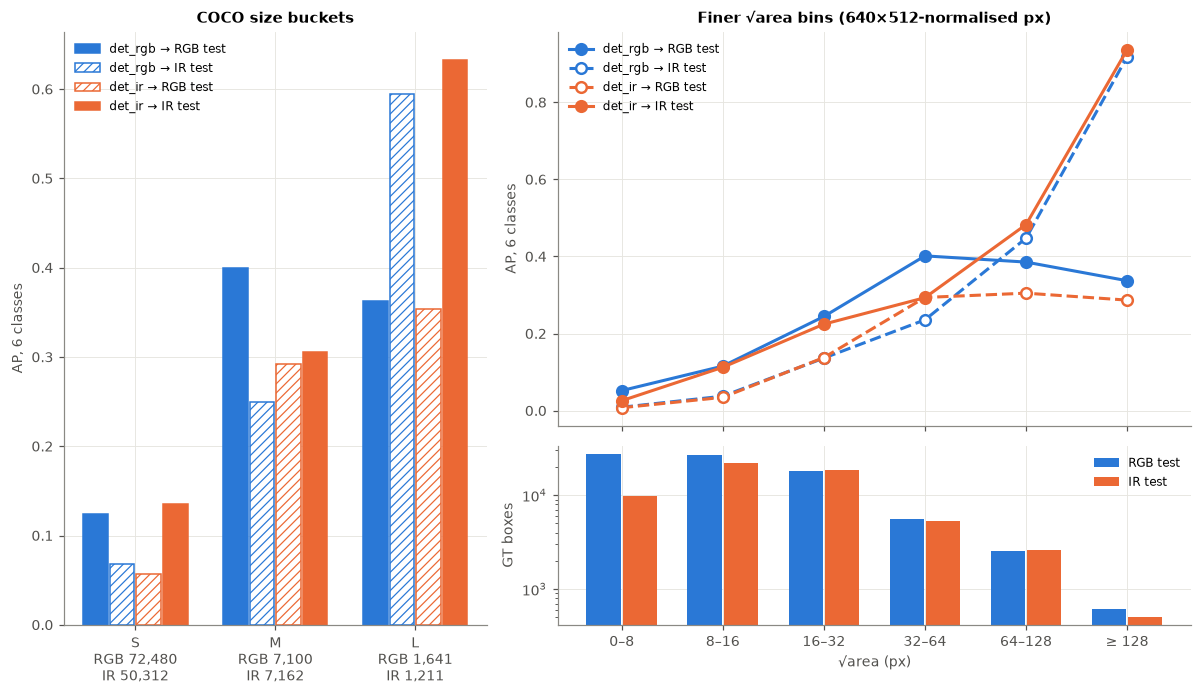

In [10]:
fig = plt.figure(figsize=(11, 6.4))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.5], height_ratios=[2.2, 1])
ax_coco = fig.add_subplot(gs[:, 0])
ax_fine = fig.add_subplot(gs[0, 1])
ax_n = fig.add_subplot(gs[1, 1], sharex=ax_fine)

sizes = ["S", "M", "L"]
x = np.arange(3)
w = 0.19
for i, (h, m) in enumerate(CELLS):
    ax_coco.bar(x + (i - 1.5) * w, [M(h, m, area=s)["AP"] for s in sizes], w * 0.92, **cell_style(h, m))
ax_coco.set_xticks(x, [f"{s}\nRGB {GT_BIN['rgb'][s]:,}\nIR {GT_BIN['thermal'][s]:,}" for s in sizes])
ax_coco.set_ylabel("AP, 6 classes")
ax_coco.set_title("COCO size buckets")
cell_legend(ax_coco, loc="upper left", fontsize=8)

xf = np.arange(len(FINE))
for h, m in CELLS:
    st = cell_style(h, m)
    in_dom = HEAD_MOD[h] == m
    ax_fine.plot(xf, [M(h, m, area=b)["AP"] for b in FINE], color=st["edgecolor"], lw=2,
                 ls="-" if in_dom else "--", marker="o", ms=7, mfc=st["edgecolor"] if in_dom else "white",
                 mew=1.6, label=cell_label(h, m))
ax_fine.set_ylabel("AP, 6 classes")
ax_fine.set_title("Finer √area bins (640×512-normalised px)")
ax_fine.legend(loc="upper left", fontsize=8)
for i, m in enumerate(MODS):
    ax_n.bar(xf + (i - 0.5) * 0.36, [GT_BIN[m][b] for b in FINE], 0.34, color=MOD_COLOR[m], label=f"{MOD_LABEL[m]} test")
ax_n.set_yscale("log")
ax_n.set_ylabel("GT boxes")
ax_n.set_xticks(xf, FINE)
ax_n.set_xlabel("√area (px)")
ax_n.legend(loc="upper right", fontsize=8)
plt.setp(ax_fine.get_xticklabels(), visible=False)
fig.tight_layout()

rows = [[cell_label(h, m), *[M(h, m, area=b)["AP"] for b in FINE]] for h, m in CELLS]
rows += [["GT boxes RGB", *[GT_BIN["rgb"][b] for b in FINE]], ["GT boxes IR", *[GT_BIN["thermal"][b] for b in FINE]]]
table(["cell", *FINE], rows)

- **Small objects dominate and are hard for every cell.** 89 % (RGB) and 86 % (IR) of GT boxes are S (< 32²), and
  AP in the smallest bin (< 8 px) is 0.01–0.05. RGB test has 2.8× more boxes < 8 px than IR test (27,550 vs 9,715),
  mostly the extra signs and lights of R10.
- **In-domain, the two heads track each other up to 32 px** (0.05/0.12/0.24 RGB vs 0.03/0.11/0.22 IR). The cross-modal
  cells sit well below in-domain up to 64 px (e.g. 16–32 px: 0.14 vs 0.22–0.24).
- **Above 64 px the modalities split.** IR test keeps rising to AP 0.92–0.94 for objects ≥ 128 px with *either* head;
  RGB test plateaus at 0.29–0.39 with either head. A head-independent plateau points at the RGB test frames, for
  example large near-field objects cut by the 5:4 edge crop or blown out by headlights, not at the RGB head. That
  needs a look at the failures before it is claimed.
- `det_rgb` on IR matches `det_ir` on IR above 64 px (0.447 vs 0.483, 0.918 vs 0.936): **large objects transfer from
  RGB to IR almost losslessly.**

### 5.1 Sensitivity: detection areas in native vs normalised pixels

`coco_map` (F8, used by F15) gives the GT **normalised** areas but leaves `loadRes` to set each detection's area to
w·h in **native** FLIR px. For thermal (640×512) the two are the same. For RGB (1224×1024 and 1024×768) a detection's
native area is 2.4–3.8× its normalised area, so an unmatched RGB detection is counted in a larger size range than a
GT box of the same physical size. AP over all sizes does not change (one range covers everything); the size buckets
do. The table re-scores the two RGB-test cells with detection areas normalised like the GT.

In [11]:
rows = []
for h in HEADS:
    for key in ["S", "M", "L", *FINE]:
        nat, nrm = M(h, "rgb", area=key)["AP"], M(h, "rgb", area=key, dt_area="normalised")["AP"]
        rows.append([cell_label(h, "rgb"), key, nat, nrm, nrm - nat])
    assert M(h, "rgb")["AP"] == M(h, "rgb", dt_area="normalised")["AP"]
table(["cell", "size", "AP (native dt area, F15)", "AP (normalised dt area)", "Δ"], rows)

| cell | size | AP (native dt area, F15) | AP (normalised dt area) | Δ |
|---|---|---|---|---|
| det_rgb → RGB test | S | 0.124 | 0.114 | -0.010 |
| det_rgb → RGB test | M | 0.400 | 0.458 | 0.058 |
| det_rgb → RGB test | L | 0.362 | 0.391 | 0.028 |
| det_rgb → RGB test | 0–8 | 0.052 | 0.016 | -0.036 |
| det_rgb → RGB test | 8–16 | 0.116 | 0.092 | -0.023 |
| det_rgb → RGB test | 16–32 | 0.244 | 0.265 | 0.021 |
| det_rgb → RGB test | 32–64 | 0.402 | 0.448 | 0.046 |
| det_rgb → RGB test | 64–128 | 0.385 | 0.523 | 0.138 |
| det_rgb → RGB test | ≥ 128 | 0.337 | 0.383 | 0.046 |
| det_ir → RGB test | S | 0.056 | 0.048 | -0.008 |
| det_ir → RGB test | M | 0.292 | 0.325 | 0.033 |
| det_ir → RGB test | L | 0.354 | 0.409 | 0.056 |
| det_ir → RGB test | 0–8 | 0.008 | 0.002 | -0.006 |
| det_ir → RGB test | 8–16 | 0.035 | 0.028 | -0.007 |
| det_ir → RGB test | 16–32 | 0.138 | 0.137 | -0.000 |
| det_ir → RGB test | 32–64 | 0.294 | 0.320 | 0.026 |
| det_ir → RGB test | 64–128 | 0.305 | 0.419 | 0.114 |
| det_ir → RGB test | ≥ 128 | 0.287 | 0.395 | 0.108 |

- **AP over all sizes is identical** (asserted), so F15's headline AP/AP50 are unaffected.
- **The size buckets move.** For `det_rgb` on RGB test, F15's APm 0.400 becomes 0.458 and APl 0.362 becomes 0.391;
  APs goes from 0.124 to 0.114. In the fine bins the shifts reach +0.14 (64–128 px). With normalised detection areas,
  RGB test still plateaus well below IR at large sizes, so the conclusion of §5 stands.
- **For F6:** the rigorous evaluator should give detections the same 640×512-normalised area as the GT. Until then,
  APs/M/L of RGB-test cells (F8 val and F15) are biased: APs slightly up, APm/APl down.

## Caveats

- **Preliminary until F6.** No bootstrap CIs. Test has 8 video pairs, and each time/weather bucket is 1–5 of them,
  so a bucket's AP is partly a per-video effect (scene, camera, traffic). Day is one pair (428 frames) and dusk one pair
  (565 frames).
- **Conditions are per video, from incomplete tags** (§0). Three pairs needed a decision; they live in `PAIR_CONDITIONS`.
- **Weather is confounded with time** in test (§4), and each weather bucket is 1–2 video pairs. Clear is one pair.
- **Fog rests on two objects**: one walking pedestrian and one static parked car, repeated over 546 frames.
- **R10.** Cross-modal cells compare different labelling densities for sign, light and bike; read person + car.
- **Subset AP averages the classes present in the subset**, and the class mix differs by bucket and by modality
  (§3 table). Compare buckets on the car rows.
- **`native` RGB edge crop** (F15 caveats): RGB GT boxes entirely in the 5:4-cropped edges cannot be detected.